<a href="https://colab.research.google.com/github/zhilyaevaviktorija/machine_learning/blob/main/DL_homeworks/Homework_1_%22rnn_tutorial_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Классификация текстов с помощью RNN (PyTorch)

- загрузка и визуализация данных;
- токенизация и словарь;
- RNN-классификатор;
- обучение, кривые, матрица ошибок;
- задания с плейсхолдерами для изменения гиперпараметров.

## 1. Окружение

In [4]:
!pip install -q datasets scikit-learn seaborn tqdm matplotlib

In [2]:
import re
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence
)

from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print(f"Using device: {device}")

Using device: cuda


## 2. Загрузка данных

In [5]:
dataset = load_dataset("fancyzhx/ag_news")

print(dataset)
print("\nПример:", dataset['train'][0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Пример: {'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [6]:
train_data = list(zip(
    dataset['train']['label'],
    dataset['train']['text']
))

test_data = list(zip(
    dataset['test']['label'],
    dataset['test']['text']
))

print(f"Обучающих примеров: {len(train_data)}")
print(f"Тестовых примеров: {len(test_data)}")

print(
    f"\nРаспределение меток: "
    f"{Counter(label for label, _ in train_data)}"
)

Обучающих примеров: 120000
Тестовых примеров: 7600

Распределение меток: Counter({2: 30000, 3: 30000, 1: 30000, 0: 30000})


## 3. Визуализация данных

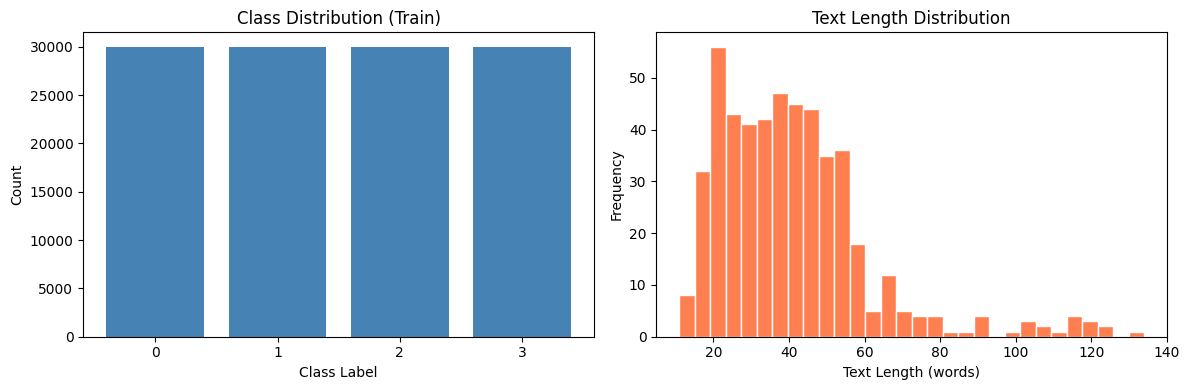

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = [label for label, _ in train_data]
label_counts = Counter(labels)

axes[0].bar(
    label_counts.keys(),
    label_counts.values(),
    color='steelblue'
)

axes[0].set_xlabel('Class Label')
axes[0].set_ylabel('Count')
axes[0].set_title('Class Distribution (Train)')
axes[0].set_xticks([0, 1, 2, 3])

lengths = [
    len(text.split())
    for _, text in train_data[:500]
]

axes[1].hist(
    lengths,
    bins=30,
    color='coral',
    edgecolor='white'
)

axes[1].set_xlabel('Text Length (words)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Text Length Distribution')

plt.tight_layout()
plt.show()

In [8]:
print("\n=== Примеры ===")

for i in range(3):
    label, text = train_data[i]
    print(f"[Label {label}] {text[:150]}...")


=== Примеры ===
[Label 2] Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again....
[Label 2] Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and ...
[Label 2] Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expecte...


## 4. Токенизация и словарь

In [9]:
def tokenizer(text):
    """
    Простой токенизатор без torchtext.
    Приводит текст к нижнему регистру и отделяет пунктуацию.
    """
    return re.findall(
        r"\w+|[^\w\s]",
        text.lower()
    )


def yield_tokens(data):
    for _, text in data:
        yield tokenizer(text)

In [10]:
def build_vocab_from_iterator(iterator, min_freq=1):
    counter = Counter()

    for tokens in iterator:
        counter.update(tokens)

    # Индексы специальных токенов:
    # <pad> = 0
    # <unk> = 1
    vocab = {
        '<pad>': 0,
        '<unk>': 1,
    }

    frequent_tokens = [
        token
        for token, frequency in counter.items()
        if frequency >= min_freq
        and token not in ('<pad>', '<unk>')
    ]

    # Сначала частые слова, затем алфавитный порядок
    frequent_tokens.sort(
        key=lambda token: (-counter[token], token)
    )

    vocab.update({
        token: index
        for index, token in enumerate(
            frequent_tokens,
            start=2
        )
    })

    return vocab

In [126]:
# ============================================
# Задание 1: параметры построения словаря
# Попробуйте min_freq = 2 или 10. Как меняются размер словаря и качество модели?
# Почему редкие слова могут как помогать, так и мешать?
# ============================================
MIN_FREQ = 10  # <-- меняйте здесь

# Сначала строим словарь только из реальных токенов
vocab = build_vocab_from_iterator(
    yield_tokens(train_data),
    min_freq=MIN_FREQ
)

# Добавляем специальные токены вручную
# Порядок важен: <pad> должен быть первым (индекс 0), <unk> — вторым (индекс 1)

# Устанавливаем токен по умолчанию для неизвестных слов
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

print(f"Размер словаря: {len(vocab)}")
print(f"PAD_IDX = {PAD_IDX}, UNK_IDX = {UNK_IDX}")

Размер словаря: 19638
PAD_IDX = 0, UNK_IDX = 1


Результаты:
1. при min_freq = 5
Размер словаря: 27831
PAD_IDX = 0, UNK_IDX = 1
2. при min_freq = 2
Размер словаря: 44138
PAD_IDX = 0, UNK_IDX = 1
3. при min_freq = 10
Размер словаря: 19638
PAD_IDX = 0, UNK_IDX = 1

Выводы:
1. чем больше min_freq, тем меньше размер словая и наоборот;
2. при меньшем объеме словаря модель обучается быстрее, занимает меньше памяти, не переобучается;
3. редкие слова помогают, когда важны конкретные сущности, и мешают, когда попадает лишний шум, замедняющий работу модели.

## 5. Предобработка и Dataset

In [127]:
# ============================================
# Задание 2: длина последовательности (обрезка)
# Попробуйте MAX_LEN = 128, 256, 512. Как меняются скорость обучения и точность?
# Почему у RNN может не быть выигрыша от очень длинных последовательностей?
# ============================================
MAX_LEN = 128  # <-- меняйте здесь

In [128]:
def text_pipeline(text):
    tokens = tokenizer(text)

    ids = [
        vocab.get(token, UNK_IDX)
        for token in tokens
    ]

    if len(ids) > MAX_LEN:
        ids = ids[:MAX_LEN]

    # На случай пустого текста
    if len(ids) == 0:
        ids = [UNK_IDX]

    return ids


def label_pipeline(label):
    return label

In [129]:
class AGNewsDataset(torch.utils.data.Dataset):
    def __init__(
        self,
        data,
        text_pipeline,
        label_pipeline
    ):
        self.data = data
        self.text_pipeline = text_pipeline
        self.label_pipeline = label_pipeline

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        label, text = self.data[idx]

        ids = self.text_pipeline(text)

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(
                self.label_pipeline(label),
                dtype=torch.long
            )
        )

In [130]:
def collate_batch(batch):
    text_list, label_list = zip(*batch)

    lengths = torch.tensor(
        [len(text) for text in text_list],
        dtype=torch.long
    )

    padded = pad_sequence(
        text_list,
        batch_first=True,
        padding_value=PAD_IDX
    )

    labels = torch.stack(label_list)

    return padded, lengths, labels

In [131]:
train_dataset = AGNewsDataset(
    train_data,
    text_pipeline,
    label_pipeline
)

test_dataset = AGNewsDataset(
    test_data,
    text_pipeline,
    label_pipeline
)

## 6. DataLoader

In [132]:
# ============================================
# Задание 3: размер батча
# Попробуйте BATCH_SIZE = 32, 64, 128. Как это влияет на стабильность обучения и скорость?
# Документация: https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader
# ============================================
BATCH_SIZE = 64  # <-- меняйте здесь

In [133]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print(
    f"Количество батчей в обучении: "
    f"{len(train_loader)}"
)

Количество батчей в обучении: 1875


## 7. RNN-модель

In [88]:
class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2,
        bidirectional=False
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = (
            hidden_dim * 2
            if bidirectional
            else hidden_dim
        )

        self.fc = nn.Linear(
            rnn_output_dim,
            num_classes
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(
            self.embedding(x)
        )

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        if self.rnn.bidirectional:
            last_hidden = torch.cat(
                [hidden[-2], hidden[-1]],
                dim=1
            )
        else:
            last_hidden = hidden[-1]

        output = self.fc(
            self.dropout(last_hidden)
        )

        return output

In [136]:
class GRUClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2,
        bidirectional=False
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        # Заменяем RNN на GRU
        self.rnn = nn.GRU(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = hidden_dim * 2 if bidirectional else hidden_dim

        self.fc = nn.Linear(rnn_output_dim, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(self.embedding(x))

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # GRU возвращает (output, hidden), как и RNN, поэтому код не меняется
        _, hidden = self.rnn(packed)

        if self.rnn.bidirectional:
            last_hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)
        else:
            last_hidden = hidden[-1]

        output = self.fc(self.dropout(last_hidden))
        return output

In [137]:
# ============================================
# Задание 4: гиперпараметры модели
# Попробуйте разные комбинации и посмотрите на точность на валидации:
#   EMBED_DIM: 64, 128, 256
#   HIDDEN_DIM: 64, 128, 256
#   NUM_LAYERS: 1, 2
#   BIDIRECTIONAL: True / False
# Как размер скрытого состояния связан с числом параметров и качеством?
# ============================================
EMBED_DIM = 128       # <-- меняйте здесь
HIDDEN_DIM = 128      # <-- меняйте здесь
NUM_LAYERS = 1        # <-- меняйте здесь
BIDIRECTIONAL = True # <-- меняйте здесь (True/False)
DROPOUT = 0.2

In [135]:
model = RNNClassifier(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=4,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=BIDIRECTIONAL
).to(device)

print(model)

print(
    f"Количество обучаемых параметров: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

RNNClassifier(
  (embedding): Embedding(19638, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=256, out_features=4, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)
Количество обучаемых параметров: 2,580,740


In [139]:
model = GRUClassifier(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=4,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=BIDIRECTIONAL
).to(device)

print(model)

print(
    f"Количество обучаемых параметров: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

GRUClassifier(
  (embedding): Embedding(19638, 128, padding_idx=0)
  (rnn): GRU(128, 128, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=256, out_features=4, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)
Количество обучаемых параметров: 2,712,836


## 8. Обучение и проверка

In [140]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for texts, lengths, labels in tqdm(
        loader,
        desc="Training"
    ):
        texts = texts.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(texts, lengths)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        predictions = logits.argmax(dim=1)

        total_loss += (
            loss.item() * labels.size(0)
        )

        total_correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [141]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for texts, lengths, labels in tqdm(
            loader,
            desc="Evaluating"
        ):
            texts = texts.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            logits = model(texts, lengths)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            total_loss += (
                loss.item() * labels.size(0)
            )

            total_correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            total_samples += labels.size(0)

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return (
        total_loss / total_samples,
        total_correct / total_samples,
        all_preds,
        all_labels
    )

In [142]:
# ============================================
# Задание 5: параметры оптимизатора
# Попробуйте LEARNING_RATE = 1e-3, 5e-4, 1e-4.
# Как скорость обучения влияет на сходимость и стабильность?
# Документация: https://pytorch.org/docs/stable/optim.html#torch.optim.Adam
# ============================================
LEARNING_RATE = 1e-3  # <-- меняйте здесь
NUM_EPOCHS = 5        # <-- меняйте здесь

In [143]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_acc, _, _ = evaluate(
        model,
        test_loader,
        criterion
    )

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Evaluating: 100%|██████████| 119/119 [00:01<00:00, 103.97it/s]


Epoch 1/5 | Train Loss: 0.4891 | Train Acc: 0.8144 | Val Loss: 0.2978 | Val Acc: 0.8982


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 104.00it/s]


Epoch 2/5 | Train Loss: 0.2593 | Train Acc: 0.9095 | Val Loss: 0.2537 | Val Acc: 0.9117


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 106.02it/s]


Epoch 3/5 | Train Loss: 0.2044 | Train Acc: 0.9294 | Val Loss: 0.2348 | Val Acc: 0.9220


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 63.68it/s]


Epoch 4/5 | Train Loss: 0.1707 | Train Acc: 0.9395 | Val Loss: 0.2364 | Val Acc: 0.9228


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 100.00it/s]

Epoch 5/5 | Train Loss: 0.1454 | Train Acc: 0.9490 | Val Loss: 0.2389 | Val Acc: 0.9264


## 9. Кривые обучения

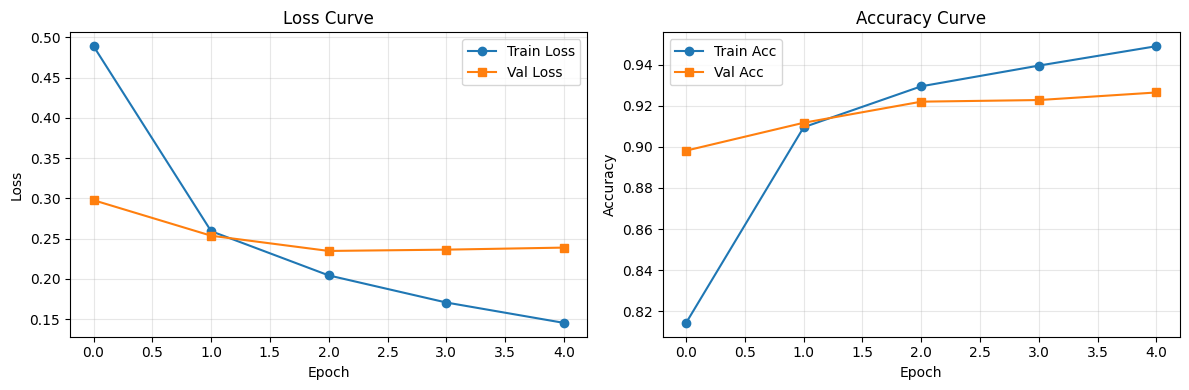

In [144]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    history['train_loss'],
    label='Train Loss',
    marker='o'
)

axes[0].plot(
    history['val_loss'],
    label='Val Loss',
    marker='s'
)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history['train_acc'],
    label='Train Acc',
    marker='o'
)

axes[1].plot(
    history['val_acc'],
    label='Val Acc',
    marker='s'
)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Curve')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Матрица ошибок и classification report

In [145]:
val_loss, val_acc, all_preds, all_labels = evaluate(
    model,
    test_loader,
    criterion
)

print(f"Test loss: {val_loss:.4f}")
print(f"Test accuracy: {val_acc:.4f}")

Evaluating: 100%|██████████| 119/119 [00:01<00:00, 101.75it/s]

Test loss: 0.2389
Test accuracy: 0.9264


In [146]:
class_names = [
    'World',
    'Sports',
    'Business',
    'Sci/Tech'
]

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

       World       0.94      0.93      0.94      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.90      0.89      0.90      1900
    Sci/Tech       0.90      0.90      0.90      1900

    accuracy                           0.93      7600
   macro avg       0.93      0.93      0.93      7600
weighted avg       0.93      0.93      0.93      7600



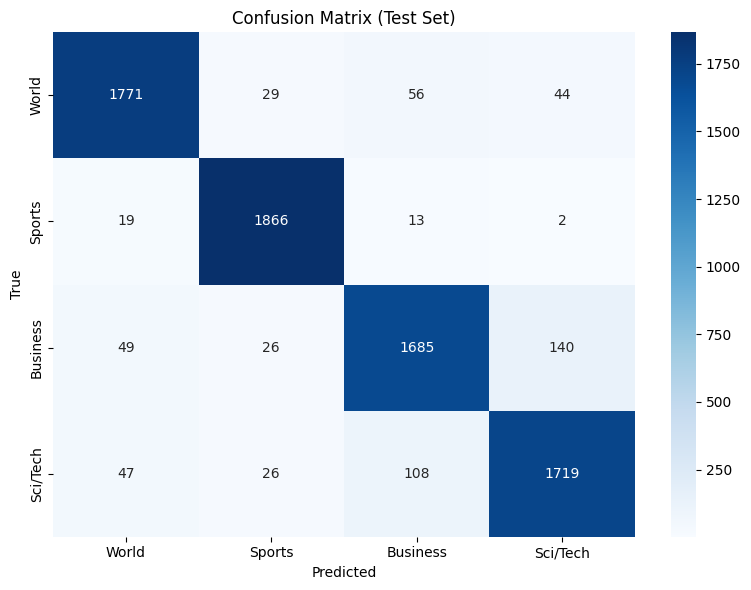

In [147]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

## 11. Контрольные вопросы для студентов

1. **Почему в этом ноутбуке используется `pack_padded_sequence`?**  
   Что произойдёт, если убрать `pack_padded_sequence` и просто подать `padded` тензор в RNN?

   Ответ: pack_padded_sequence игнорирует pad-токены при проходе через RNN, чтобы они не влияли на скрытое состояние. Если ее убрать и подать просто padded-тензор, RNN будет обрабатывать нули как обычные слова. Это замедлит обучение и испортит качество, так как скрытое состояние в конце последовательности будет зависеть от количества паддинга, а не от реального текста.

2. **Как `min_freq` влияет на размер словаря и на количество параметров embedding-слоя?**  
   Оцените, как меняется число обучаемых параметров при `MIN_FREQ = 2` и `MIN_FREQ = 10`.

   Ответ: чем выше `MIN_FREQ`, тем меньше слов попадает в словарь (редкие заменяются на unk). При `MIN_FREQ`= 10 словарь = 19 638, параметров = 2.51 млн. При `MIN_FREQ` = 2 словарь = 44 138, параметров = 5.65 млн, т.е. в 2 раза больше.

3. **Что означает `lengths.cpu()` в вызове `pack_padded_sequence`?**  
   Почему длины должны быть на CPU, а не на GPU?

   Ответ: это перенос тензора длин на процессор. Функция `pack_padded_sequence` требует, чтобы длины находились в оперативной памяти (CPU), а не в видеопамяти (GPU), иначе PyTorch выдаст ошибку несовпадения устройств. При этом сам тензор эмбеддингов остается на GPU.

4. **Почему при `BIDIRECTIONAL = True` используется `torch.cat([hidden[-2], hidden[-1]], dim=1)`?**  
   Что хранится в `hidden[-2]` и `hidden[-1]`?
   
   Ответ: в двунаправленной RNN `hidden` имеет размерность (`num_layers` * 2, `batch`, `hidden_dim`). `hidden[-2]` — это финальное скрытое состояние прямого прохода, а `hidden[-1]` — обратного. Они конкатенируются по размерности признаков (`dim` = 1), чтобы классификатор `fc` получил полный контекст текста с обеих сторон.

5. **Как размер `HIDDEN_DIM` связан с числом параметров RNN?**  
   Выведите формулу для числа параметров `nn.RNN` (без bias и с bias).

   Ответ: Пусть I — размер входа (`embed_dim`), H — скрытый размер (`hidden_dim`).
   Без bias: I * H + H * H. С bias (по умолчанию): I * H + H * H + H (для одного слоя и одного направления). Если слоев L или направлений 2, формула умножается (для первого слоя вход I, для последующих — H).

6. **Почему `clip_grad_norm_` особенно важен для RNN?**  
   С каким явлением он борется?

   Ответ: он обрезает норму градиента, если она превышает заданный порог. Это борется с взрывом градиентов (exploding gradients) — частой проблемой RNN, когда при обратном распространении ошибки градиенты становятся огромными и ломают веса.

7. **Что произойдёт, если `MAX_LEN` сделать очень большим (например, 2048)?**  
   Как это повлияет на время обучения, память и качество?

   Ответ: время обучения сильно вырастет. Тензоры батчей станут огромными. Для простой RNN качество может упасть (из-за затухания градиентов модель забудет начало текста). Для коротких новостей AG News 2048 — это избыточно.

8. **Почему `padding_idx=PAD_IDX` важен в `nn.Embedding`?**  
   Что произойдёт, если его не указывать?

   Ответ: он принудительно зануляет вектор для токена pad и отключает обновление градиентов для этого вектора при обучении. Если его не указывать, модель будет учить эмбеддинг для "пустоты", тратя ресурсы, а сам паддинг начнет вносить случайный шум в предсказания.

9. **Как интерпретировать матрицу ошибок?**  
   Какие классы чаще всего путаются и почему?

   Ответ: по диагонали — правильные ответы. вне диагонали — ошибки (по строкам — истинный класс, по столбцам — предсказанный). В данном датасете при экспериментах чаще всего путаются Business и Sci/Tech, а также World и Sports.

10. **Почему accuracy может быть не лучшей метрикой для этой задачи?**  
    Посмотрите на `classification_report` и объясните, какие метрики здесь информативнее.

    Ответ: в AG News классы сбалансированы, поэтому accuracy здесь приемлема. Однако она не показывает природу ошибок. Информативнее Precision, Recall и F1-score по каждому классу.

## 12. Домашнее задание

### Часть A. Эксперименты с гиперпараметрами

Проведите **минимум 5 экспериментов**, меняя по одному гиперпараметру за раз:

1. `MIN_FREQ`: 2, 5, 10
2. `MAX_LEN`: 128, 256, 512
3. `BATCH_SIZE`: 32, 64, 128
4. `EMBED_DIM` / `HIDDEN_DIM`: (64, 64), (128, 128), (256, 256)
5. `NUM_LAYERS`: 1, 2
6. `BIDIRECTIONAL`: True / False
7. `LEARNING_RATE`: 1e-3, 5e-4, 1e-4

Для каждого эксперимента зафиксируйте:
- размер словаря;
- число параметров модели;
- время одной эпохи;
- `val_loss` и `val_acc` после 3–5 эпох.

Сведите результаты в таблицу и постройте графики зависимости `val_acc` от каждого гиперпараметра.

### Часть B. Анализ ошибок

1. Найдите **10 примеров**, на которых модель ошибается.
2. Для каждого примера укажите: истинный класс, предсказанный класс, текст (можно первые 200 символов).
3. Предложите **гипотезы**, почему модель ошибается (короткий текст, смешанная тематика, редкие слова и т.д.).
4. Предложите **2–3 идеи**, как улучшить модель именно на этих примерах.

### Часть C. Улучшение архитектуры

Замените `nn.RNN` на одну из архитектур:
- `nn.LSTM`
- `nn.GRU`
- двунаправленный LSTM/GRU

Сравните с базовой RNN по тем же метрикам. Объясните, почему LSTM/GRU часто работают лучше на длинных последовательностях.

### Часть D. Мини-исследование

Проверьте гипотезу: **«чем длиннее текст, тем лучше модель его классифицирует»**.

1. Разбейте тестовые примеры на группы по длине (например, 0–50, 51–100, 101–200, 200+ слов).
2. Посчитайте accuracy для каждой группы.
3. Постройте график зависимости accuracy от длины.
4. Сформулируйте вывод: подтверждается ли гипотеза?

### Формат сдачи

- Ноутбук `.ipynb` со всеми выполненными ячейками.
- Краткий отчёт (markdown внутри ноутбука): таблица экспериментов, графики, анализ ошибок, выводы.
- Ссылка на GitHub / Colab или сам файл.

###Часть A. Эксперименты с гиперпараметрами

| № | Измененные параметры | Размер словаря | Число параметров модели | Время эпохи | `val_loss` (5 эпох) | `val_acc` (5 эпох) |
|-------------|-------------|-------------|-------------|-------------|-------------|-------------|
| 1 | baseline | 19638 | 2,547,204 | 21-24 сек | 0.4167 | 0.8707 |
| 2 | `MIN_FREQ` = 2 | 44138 | 5,683,204 | 25 сек | 0.4201 | 0.8778 |
| 3 | `MAX_LEN` = 256 | 19638 | 2,547,204 | 23-24 сек | 0.4520 | 0.8646 |
| 4 | `BATCH_SIZE` = 128 | 19638 | 2,547,204 | 14-16 сек | 0.4763 | 0.8603 |
| 5 | `BIDIRECTIONAL` = True | 19638 | 2,580,740 | 29-35 сек | 0.3140 | 0.8988 |

**Выводы по итерациям**
1. Baseline:
- `MIN_FREQ` = 10,
- `MAX_LEN` = 128,
- `BATCH_SIZE` = 64,
- `EMBED_DIM` = 128,
- `HIDDEN_DIM` = 128,
- `NUM_LAYERS` = 1,
- `BIDIRECTIONAL` = False,
- `LEARNING_RATE` = 1e-3,
- `NUM_EPOCHS` = 5
- Первая итерация показала неплохой результат точности и времени обучения, но допустила 199 ошибок между Business и Sci/Tech.

2. **`MIN_FREQ` = 2**
- Словарь увеличился до 44 138 слов, из-за этого количество параметров модели увеличилось более чем в 2 раза до 5,68 млн, время эпохи увеличилось до 25 сек.
- Качество на валидации выросло на 0.71% (с 0.8707 до 0.8778). Это говорит о том, что редкие слова несут в себе полезную информацию для классификации новостей.
- Модель стала лучше различать World и Sci/Tech (точность по ним выросла до 0.85-0.88), но Business всё еще иногда путается с Sci/Tech (199 ошибок).

3. **`MAX_LEN` = 256**
- Время эпохи практически не изменилось (с 25 сек до 23 сек).
- `val_acc` упала с 87.07% до 86.46%. Модель стала хуже справляться с текстами.
- Модель стала хуже различать Business и Sci/Tech (427 ошибок).

4. **`BATCH_SIZE` = 128**
- За счет снижения количества батчей с 1875 до 938, сократилось время эпохи  до 14-16 сек.
- Точность на тесте упала с 87.07% до 86.03%.
- Модель стала хуже различать Business (recall упал до 0.77) и начала часто путать его со Sci/Tech (353 ошибки).
- При `BATCH_SIZE` = 128 наблюдается более быстрое обучение, но значительное снижение качества.

5. **`BIDIRECTIONAL` = True**
- Количество параметров выросло с 2,547,204 до 2,580,740.
- Время эпохи выросло до 29-35 сек.
- Точность выросла на 2.81% (с 0.8707 до 0.8988).
- `val_loss` упал с 0.4167 до 0.3140 => модель стала меньше ошибаться.
- Число ошибок между Business и Sci/Tech сократилось.

Таким образом, `BIDIRECTIONAL = True` показывает лучший результат по качеству (89.88%), но требует больше времени.

Влияние гиперпараметров на Val Accuracy

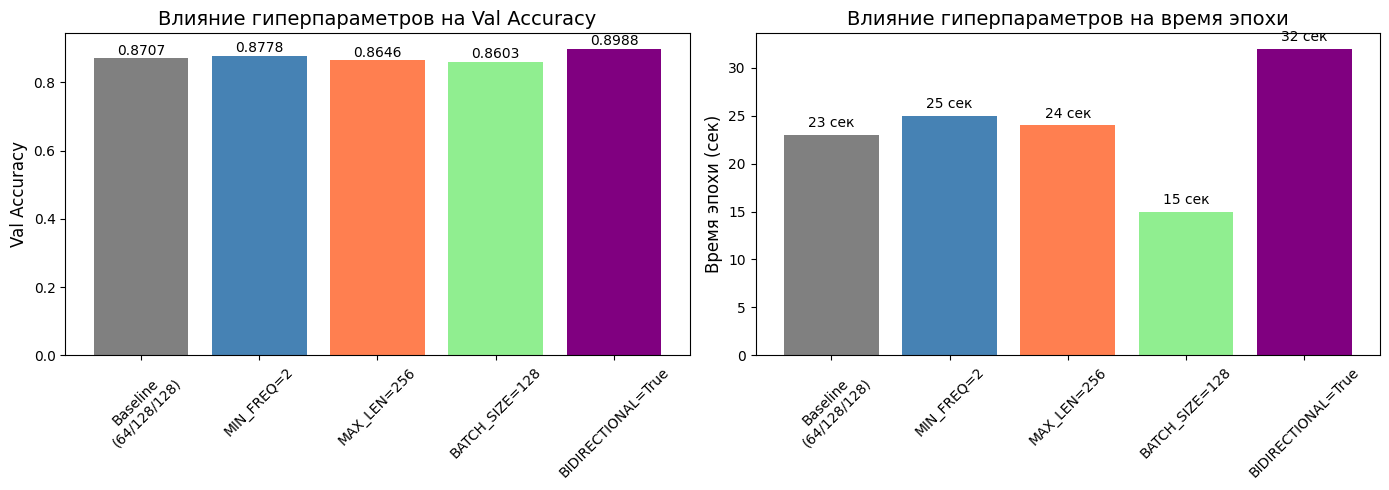

In [125]:
import matplotlib.pyplot as plt
import numpy as np

# Данные из пяти итераций
experiments = [
    "Baseline\n(64/128/128)",
    "MIN_FREQ=2",
    "MAX_LEN=256",
    "BATCH_SIZE=128",
    "BIDIRECTIONAL=True"
]
val_acc = [0.8707, 0.8778, 0.8646, 0.8603, 0.8988]
time_epoch = [23, 25, 24, 15, 32]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Влияние на Val Accuracy
bars1 = axes[0].bar(experiments, val_acc, color=['gray', 'steelblue', 'coral', 'lightgreen', 'purple'])
axes[0].set_title('Влияние гиперпараметров на Val Accuracy', fontsize=14)
axes[0].set_ylabel('Val Accuracy', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# Подписываем значения над столбцами
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.001, f'{yval:.4f}',
                 ha='center', va='bottom', fontsize=10)

# График 2: Влияние на время эпохи
bars2 = axes[1].bar(experiments, time_epoch, color=['gray', 'steelblue', 'coral', 'lightgreen', 'purple'])
axes[1].set_title('Влияние гиперпараметров на время эпохи', fontsize=14)
axes[1].set_ylabel('Время эпохи (сек)', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval} сек',
                 ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

Часть B. Анализ ошибок

In [105]:
import torch

# Настраиваем модель на режим оценки
model.eval()

# Словарь для перевода индексов в названия классов
class_names = ['World', 'Sports', 'Business', 'Sci/Tech']

error_count = 0
print("10 примеров ошибок модели\n")

# Проходим по тестовому датасету по одному примеру
for i in range(len(test_dataset)):
    # Получаем данные
    text_tensor, true_label = test_dataset[i]

    # Достаем исходный текст из test_data
    raw_text = test_data[i][1]

    # Подготавливаем тензор для модели с размерностью батча
    text_input = text_tensor.unsqueeze(0).to(device)
    length_input = torch.tensor([len(text_tensor)]).to(device)

    # Делаем предсказание
    with torch.no_grad():
        logits = model(text_input, length_input)
        pred_label = logits.argmax(dim=1).item()

    # Если модель ошиблась
    if pred_label != true_label.item():
        error_count += 1

        # Выводим информацию
        print(f"Ошибка № {error_count}")
        print(f"Истинный класс:    {class_names[true_label.item()]}")
        print(f"Предсказанный:     {class_names[pred_label]}")
        print(f"Текст: {raw_text[:200]}...")
        print("-" * 50)

    # Останавливаемся после 10 ошибок
    if error_count == 10:
        break

10 примеров ошибок модели

Ошибка № 1
Истинный класс:    Sci/Tech
Предсказанный:     Business
Текст: IBM to hire even more new workers By the end of the year, the computing giant plans to have its biggest headcount since 1991....
--------------------------------------------------
Ошибка № 2
Истинный класс:    Sci/Tech
Предсказанный:     Business
Текст: Some People Not Eligible to Get in on Google IPO Google has billed its IPO as a way for everyday people to get in on the process, denying Wall Street the usual stranglehold it's had on IPOs. Public bi...
--------------------------------------------------
Ошибка № 3
Истинный класс:    Sci/Tech
Предсказанный:     Business
Текст: Rivals Try to Turn Tables on Charles Schwab By MICHAEL LIEDTKE     SAN FRANCISCO (AP) -- With its low prices and iconoclastic attitude, discount stock broker Charles Schwab Corp. (SCH) represented an ...
--------------------------------------------------
Ошибка № 4
Истинный класс:    Sports
Предсказанный:     World

Ошибки были выбраны по результатам обучения при `BIDIRECTIONAL` = True.
Большинство ошибок связано с *пересечением тематик* (чаще всего бизнес и технологии) и *скрытым контекстом* (когда новость о политике или здоровье маскируется под спорт или бизнес).

- **Sci/Tech и Business**: модель чаще всего путает новости о компаниях, потому что они содержат финансовые термины (IPO, акции, рынок), но по сути являются технологическими. Ошибки 1, 2, 3, 7. Примеры слов, которые сбивают модель: "hire", "workers", "headcount", "IPO", "Wall Street", "market", "consumer", "Reuters"
- **Sports и World**: спортивные события часто имеют политический или географический контекст, что сбивает модель с толку. Ошибки 4, 9. Примеры слов, которые сбивают модель: "rules", "Olympics", "going for gold".
- **World и Business**: влияние геополитики на экономику. Ошибка 5. Примеры слов, которые сбивают модель: "world oil market".
- **Business и Sci/Tech**: новости о ритейле и товарах ошибочно относятся к технологиям. Ошибки 6 и 10. Примеры слов, которые сбивают модель: "style-conscious", "fashions", "teens", "Intel", "high-definition TVs", "video display chip".
- **Sci/Tech и Sports**: слово "running into" ошибочно воспринято как спорт.


Идеи для улучшения модели на 10 примерах:
1. Попробовать добавить архитектуру LSTM/GRU, чтобы модель лучше запоминала весь тексте и не забывала его начало.
2. Применить Fine-tuning на сложных примерах, где пересекаются тексты, например, по бизнесу и технологиям, чтобы дообучить модель именно на них, указав правильный класс.

##Часть C. Улучшение архитектуры

Для улучшения результатов взяли архитектуру GRU. Результаты: Val Loss: 0.2389 | Val Acc: 0.9264.

- Модель стала гораздо лучше обучаться (Val Acc при RNN (BIDIRECTIONAL = True) = 0.8988, 32 сек, при GRU = 0.9264, 29 сек).
- На 5-й эпохе модель показала результат Val Acc: 0.9264 и Train Acc: 0.9490. Небольшой разры между Train Acc и Val Acc свидетельствует о небольшом переобучении модели.

Почему LSTM/GRU работают лучше на длинных последовательностях?

- Эти архитекруты позволяют бороться с затуханием градиента, т.е. не терять важную информацию.
- Благодаря долгосрочной памяти модель лучше запоминает важную информацию на длинных текстах.
- Несмотря на то, что архитектура GRU сложнее, чем RNN, при этом она работает лучше и дает более качественные результаты при минимально затраченном времени.

##Часть D. Мини-исследование

Проверка гипотезы: «чем длиннее текст, тем лучше модель его классифицирует».

In [112]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Собираем предсказания и длины текстов
model.eval()
all_preds = []
all_labels = []
text_lengths = []

for i in range(len(test_dataset)):
    # Получаем исходный текст, чтобы посчитать слова
    raw_text = test_data[i][1]
    word_count = len(raw_text.split())

    # Получаем тензоры для модели
    text_tensor, true_label = test_dataset[i]
    text_input = text_tensor.unsqueeze(0).to(device)
    length_input = torch.tensor([len(text_tensor)]).to(device)

    # Делаем предсказание
    with torch.no_grad():
        logits = model(text_input, length_input)
        pred_label = logits.argmax(dim=1).item()

    all_preds.append(pred_label)
    all_labels.append(true_label.item())
    text_lengths.append(word_count)

In [113]:
# 2. Разбиваем на группы и считаем accuracy
bins = [0, 50, 100, 200, float('inf')]
bin_labels = ['0-50 слов', '51-100 слов', '101-200 слов', '200+ слов']
accuracies = []
counts = []

for i in range(len(bins)-1):
    # Находим индексы текстов, попадающих в диапазон
    indices = [j for j, length in enumerate(text_lengths) if bins[i] < length <= bins[i+1]]

    if len(indices) > 0:
        # Считаем accuracy для этой группы
        correct = sum(1 for idx in indices if all_preds[idx] == all_labels[idx])
        acc = correct / len(indices)
        accuracies.append(acc)
        counts.append(len(indices))
    else:
        accuracies.append(0)
        counts.append(0)

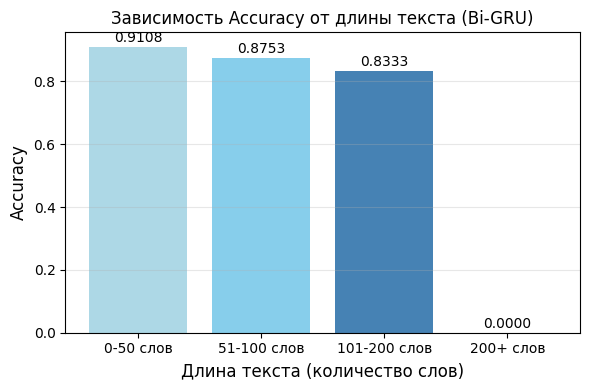


Результаты по группам:
0-50 слов: Accuracy = 0.9108 (текстов: 7109)
51-100 слов: Accuracy = 0.8753 (текстов: 473)
101-200 слов: Accuracy = 0.8333 (текстов: 18)
200+ слов: Accuracy = 0.0000 (текстов: 0)


In [123]:
# 3. Строим график
plt.figure(figsize=(6, 4))
bars = plt.bar(bin_labels, accuracies, color=['lightblue', 'skyblue', 'steelblue', 'navy'])

# Подписываем значения accuracy над столбцами
for bar, acc in zip(bars, accuracies):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005,
             f'{acc:.4f}',
             ha='center', va='bottom', fontsize=10)

plt.title('Зависимость Accuracy от длины текста (Bi-GRU)', fontsize=12)
plt.xlabel('Длина текста (количество слов)', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\nРезультаты по группам:")
for label, acc, count in zip(bin_labels, accuracies, counts):
    print(f"{label}: Accuracy = {acc:.4f} (текстов: {count})")

Для проверки гипотезы тестовая выборка модели Bi-GRU была разбита на 4 группы по количеству слов.
- Гипотеза не подтвердилась, поскольку результаты показывают, что чем длиннее текст, тем ниже значение accuracy (в текстах со 101-200 словами Accuracy = 0.8333, в текстах с 0-50 словами Accuracy = 0.9108).
- Коротких текстов гораздо меньше, а тексты с более 200 словами в тестовой выборке отсутствуют. Это связано с тем, что в датасете собраны в основном короткие новостные заметки.
- Модель лучше определяет категорию новости на коротких текстах, поскольку на более длинных в тексте присутствует смешение тем, из-за чего модель может путаться.
- В более длинных текстах больше лишней лексики.
- Также это подтверждается выводом из части А о том, что увеличение `MAX_LEN` не дало прироста accuracy.